# Proyecto de Aplicación
## Pontifica Universidad Javeriana
## Especialización en IA

## Prompt Solution Client
## Grupo 6 - Agent Fintech

* Daniel Oviedo

* Julian Olaya

* Juan Pablo Rivera

* Wilmar Roa

In [ ]:
#!pip install -q imbalanced-learn

"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


## Fase 1: Comprensión del Negocio y Configuración Inicial

In [20]:
# 1. Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
%matplotlib inline

# 2. Cargar el dataset consolidado
df = pd.read_csv('dataset_medios_pago_sintetico.csv')
print(f"Dataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.")

Dataset cargado con éxito: 5000 filas y 23 columnas.


In [21]:
df.head()

,tx_id,timestamp,user_id,user_avg_ticket_size,user_cashback_responsiveness,user_credit_limit_utilization,user_balance_account_ratio,merchant_id,merchant_name,mcc_code,...,merchant_tx_volume_30d,tx_amount,tx_hour,tx_day_of_week,tx_channel,is_payroll_day,incentive_active_flag,incentive_pct,incentive_value_cop,target_chosen_payment_method
0,TX-100000,2025-01-05 20:51:00,USR-1275,93900.0,0.64,0.09,7.55,MERCH-537,Rodríguez-Camargo - Restaurantes,5812,...,1624,49900.0,20,6,QR_DYNAMIC,False,True,0.05,2500.0,DIRECT_ACCOUNT_TRANSFER
1,TX-100001,2025-06-08 15:52:00,USR-1124,105400.0,0.64,0.46,3.16,MERCH-525,"Pardo, Álvarez and Hoyos - Supermercados",5411,...,1377,124100.0,15,6,POS_PHYSICAL,False,True,0.15,18600.0,DIRECT_ACCOUNT_TRANSFER
2,TX-100002,2025-03-04 14:19:00,USR-1236,39900.0,0.78,0.35,5.63,MERCH-573,Salazar-Yepes - Restaurantes,5812,...,473,38600.0,14,1,QR_STATIC,False,True,0.05,1900.0,DIRECT_ACCOUNT_TRANSFER
3,TX-100003,2025-05-02 08:40:00,USR-1194,252400.0,0.90,0.51,0.57,MERCH-571,Rivera Group - Restaurantes,5812,...,3189,52100.0,8,4,QR_DYNAMIC,False,True,0.20,10400.0,DEBIT_CARD
4,TX-100004,2025-05-25 10:57:00,USR-1331,72600.0,0.27,0.18,4.46,MERCH-543,González LLC - Farmacias,5912,...,1974,46900.0,10,6,QR_STATIC,False,False,0.00,0.0,DIRECT_ACCOUNT_TRANSFER


## Fase 2: Comprensión de los Datos (Data Understanding & EDA)

In [22]:
# 1. Resumen estructural y tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tx_id                          5000 non-null   object 
 1   timestamp                      5000 non-null   object 
 2   user_id                        5000 non-null   object 
 3   user_avg_ticket_size           5000 non-null   float64
 4   user_cashback_responsiveness   5000 non-null   float64
 5   user_credit_limit_utilization  5000 non-null   float64
 6   user_balance_account_ratio     5000 non-null   float64
 7   merchant_id                    5000 non-null   object 
 8   merchant_name                  5000 non-null   object 
 9   mcc_code                       5000 non-null   int64  
 10  mcc_category                   5000 non-null   object 
 11  merchant_avg_ticket_size       5000 non-null   float64
 12  merchant_accepts_installment   5000 non-null   b

C:\Users\juanp\AppData\Local\Temp\ipykernel_32280\988493413.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='target_chosen_payment_method', palette='viridis')


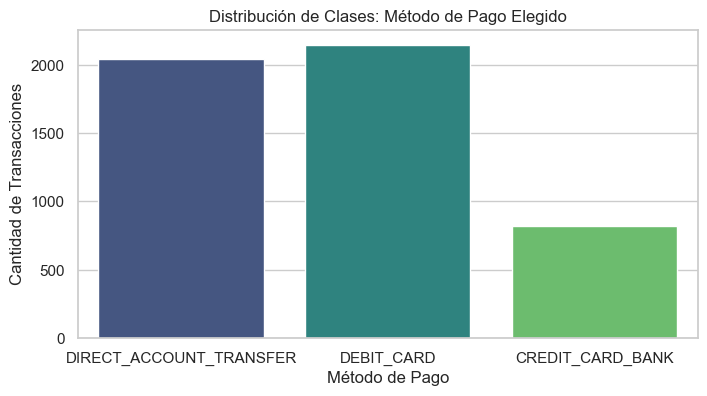

In [23]:
# 2. Distribución de la variable objetivo (Target Balance)
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x='target_chosen_payment_method', palette='viridis')
plt.title('Distribución de Clases: Método de Pago Elegido')
plt.ylabel('Cantidad de Transacciones')
plt.xlabel('Método de Pago')
plt.show()

C:\Users\juanp\AppData\Local\Temp\ipykernel_32280\3734559181.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='mcc_category', y='tx_amount', palette='Set2')


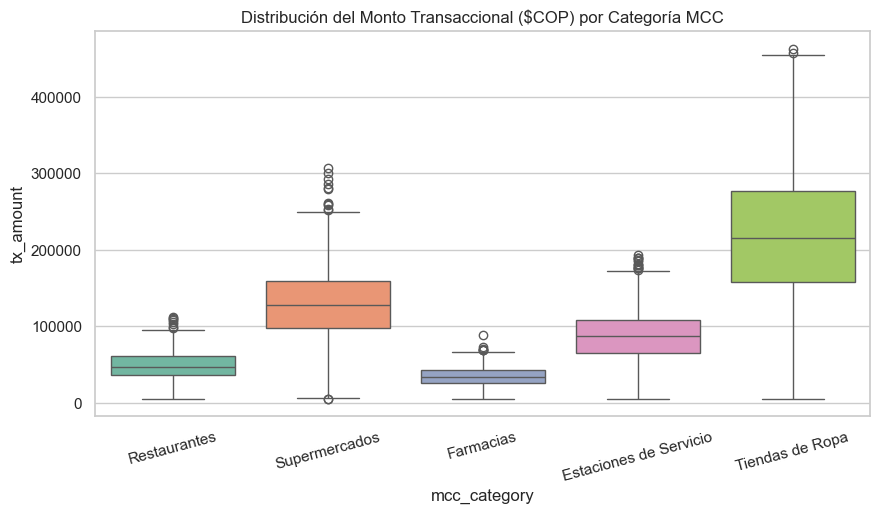

In [24]:
# 3. Análisis de Montos por Categoría
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='mcc_category', y='tx_amount', palette='Set2')
plt.title('Distribución del Monto Transaccional ($COP) por Categoría MCC')
plt.xticks(rotation=15)
plt.show()

### **Descripción de Variables**

**1.** Identificadores y Contexto Transaccional (No predictors / Metadata):

`tx_id`: Identificador único de la transacción (llave primaria)

`timestamp`: Fecha y hora exacta del evento

`user_id`: Identificador anonimizado del cliente

`merchant_id` / `merchant_name`: Identificador y nombre del establecimiento


**2.** Variables del Perfil de Usuario (Customer Features)

`user_avg_ticket_size`: Ticket promedio de compra histórico del usuario

`user_cashback_responsiveness`: Sensibilidad o propensión histórica al ahorro/cashback ($0.0$ a $1.0$)

`user_credit_limit_utilization`: Porcentaje de uso actual de la tarjeta de crédito ($0.0$ a $1.0$)

`user_balance_account_ratio`: Coeficiente de liquidez actual ($\text{Saldo en cuenta} / \text{Monto de compra}$).

**3.** Variables del Comercio y Entorno (Merchant & Context Features):

`mcc_code` / `mcc_category`: Código estándar y categoría del negocio (Restaurantes, Supermercados, etc.)

`merchant_avg_ticket_size`: Ticket promedio habitual que se factura en el comercio

`merchant_accepts_installment`: Flag booleano (True/False) de si el comercio permite diferir a cuotas

`merchant_tx_volume_30d`: Volumen transaccional del comercio en los últimos 30 días (popularidad/confianza)

`tx_amount`: Monto total cobrado en la caja o QR

`tx_hour`: Hora del día ($0$ a $23$)

`tx_day_of_week`: Día de la semana ($0 = \text{Lunes}$, $6 = \text{Domingo}$)

`tx_channel`: Canal de cobro (QR_DYNAMIC, QR_STATIC, POS_PHYSICAL, E_COMMERCE_GATEWAY)

`is_payroll_day`: Flag booleano que indica si la transacción ocurre en días de pago de nómina/quincena

`incentive_active_flag`: Flag booleano que indica si existe convenio o beneficio activo en esa categoría

**4.** Variable Objetivo (Target Label)

`target_chosen_payment_method`: Clase a predecir por el algoritmo:   DIRECT_ACCOUNT_TRANSFER (Transferencia por QR / Ahorros)   CREDIT_CARD_BANK (Tarjeta de Crédito)   DEBIT_CARD (Tarjeta Débito)  

## Fase 3: Preparación de los Datos (Data Preparation & Feature Engineering)

In [25]:
# FASE 3: PREPARACIÓN DE DATOS Y REBALANCEO CON SMOTE

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE

# 1. Cargar dataset v10
df = pd.read_csv('dataset_medios_pago_sintetico.csv')

ignore_cols = [
    'tx_id', 'timestamp', 'user_id', 'merchant_id', 'merchant_name',
    'target_chosen_payment_method'
]

X = df.drop(columns=ignore_cols)
y = df['target_chosen_payment_method']

# 2. Definir tipos de variables
categorical_cols = ['mcc_category', 'tx_channel']

numeric_cols = [
    'user_avg_ticket_size', 'user_cashback_responsiveness',
    'user_credit_limit_utilization', 'user_balance_account_ratio',
    'mcc_code', 'merchant_avg_ticket_size', 'merchant_tx_volume_30d',
    'tx_amount', 'tx_hour', 'tx_day_of_week',
    'incentive_pct', 'incentive_value_cop'
]

bool_cols = [
    'merchant_accepts_installment', 'is_payroll_day', 'incentive_active_flag'
]

# 3. Pipeline de Preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('bool', 'passthrough', bool_cols)
    ]
)

# 4. División Train/Test estratificada (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Transformar X_train para aplicar SMOTE
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Codificar Target a enteros
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# 6. Aplicar SMOTE sobre X_train_processed (Exclusivo en Entrenamiento)
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train_encoded)

print("✅ Fase 3 Completada con Rebalanceo SMOTE:")
print(f"   - Muestras X_train pre-SMOTE: {pd.Series(y_train_encoded).value_counts().to_dict()}")
print(f"   - Muestras X_train post-SMOTE: {pd.Series(y_train_resampled).value_counts().to_dict()}")

✅ Fase 3 Completada con Rebalanceo SMOTE:
   - Muestras X_train pre-SMOTE: {1: 1717, 2: 1630, 0: 653}
   - Muestras X_train post-SMOTE: {0: 1717, 2: 1717, 1: 1717}


## Fase 4: Modelado (Modeling - XGBoost Multi-Class)

In [26]:
# FASE 4: ENTRENAMIENTO DEL MODELO XGBOOST

from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

# 1. Calcular los pesos de muestra balanceados para corregir la función de pérdida
sample_weights_train = compute_sample_weight('balanced', y_train_resampled)

# 2. Instanciar el modelo XGBoost calibrado
xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric='mlogloss'
)

# 3. Entrenar el modelo con los datos de SMOTE y los sample weights
xgb_model.fit(
    X_train_resampled,
    y_train_resampled,
    sample_weight=sample_weights_train
)

print("✅ Fase 4 Completada: Modelo XGBoost entrenado exitosamente con pesos balanceados.")

✅ Fase 4 Completada: Modelo XGBoost entrenado exitosamente con pesos balanceados.


In [27]:
from sklearn.pipeline import Pipeline

# Unir el preprocesador (ya ajustado) y el modelo entrenado en un solo Pipeline
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

## Paso 4.1: Importancia de Variables en XGBoost

C:\Users\juanp\AppData\Local\Temp\ipykernel_32280\744850334.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


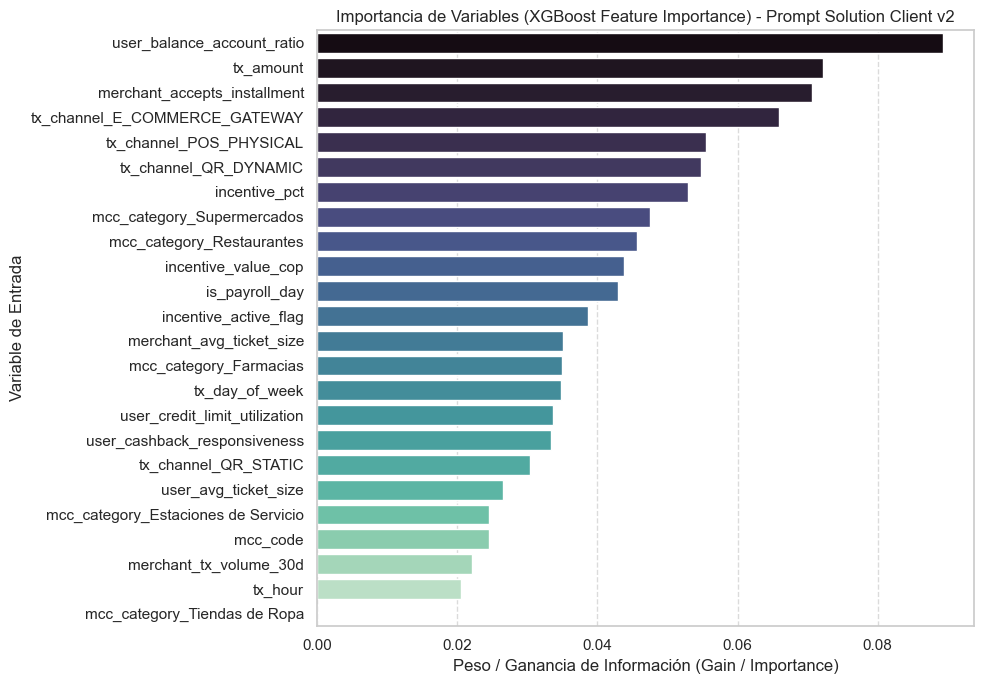

--- RANKING COMPLETO DE IMPORTANCIA DE LAS VARIABLES ---
                            feature  importance
         user_balance_account_ratio    0.089272
                          tx_amount    0.072119
       merchant_accepts_installment    0.070618
      tx_channel_E_COMMERCE_GATEWAY    0.065857
            tx_channel_POS_PHYSICAL    0.055561
              tx_channel_QR_DYNAMIC    0.054719
                      incentive_pct    0.052861
         mcc_category_Supermercados    0.047433
          mcc_category_Restaurantes    0.045703
                incentive_value_cop    0.043760
                     is_payroll_day    0.042973
              incentive_active_flag    0.038637
           merchant_avg_ticket_size    0.035139
             mcc_category_Farmacias    0.034936
                     tx_day_of_week    0.034828
      user_credit_limit_utilization    0.033706
       user_cashback_responsiveness    0.033392
               tx_channel_QR_STATIC    0.030421
               user_avg_ticket_

In [28]:
# FASE 4.1: ANÁLISIS DE IMPORTANCIA DE VARIABLES (XGBOOST FEATURE IMPORTANCE)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extraer el transformador de columnas y el modelo del Pipeline
preprocessor_step = model_pipeline.named_steps['preprocessor']
xgb_model = model_pipeline.named_steps['classifier']

# 2. Recuperar nombres de características transformadas (One-Hot Encoded)
cat_encoder = preprocessor_step.named_transformers_['cat']
cat_feature_names = list(cat_encoder.get_feature_names_out(categorical_cols))

# Concatenar todos los nombres de columnas en el orden exacto del preprocesador
all_feature_names = numeric_cols + cat_feature_names + bool_cols

# 3. Obtener el vector de importancias de XGBoost
importances = xgb_model.feature_importances_

# 4. Crear DataFrame para ordenar y visualizar
df_importance = pd.DataFrame({
    'feature': all_feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

# 5. Visualizar el gráfico horizontal de importancias
plt.figure(figsize=(10, 7))
sns.barplot(
    data=df_importance,
    x='importance',
    y='feature',
    palette='mako'
)
plt.title('Importancia de Variables (XGBoost Feature Importance) - Prompt Solution Client v2')
plt.xlabel('Peso / Ganancia de Información (Gain / Importance)')
plt.ylabel('Variable de Entrada')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 6. Imprimir el ranking estructurado en consola
print("--- RANKING COMPLETO DE IMPORTANCIA DE LAS VARIABLES ---")
print(df_importance.to_string(index=False))

## Fase 5: Evaluación del Modelo (Evaluation)

--- REPORTE DE CLASIFICACIÓN BALANCEADO ---
                         precision    recall  f1-score   support

       CREDIT_CARD_BANK       0.47      0.63      0.54       163
             DEBIT_CARD       0.61      0.64      0.62       429
DIRECT_ACCOUNT_TRANSFER       0.63      0.50      0.56       408

               accuracy                           0.58      1000
              macro avg       0.57      0.59      0.57      1000
           weighted avg       0.59      0.58      0.58      1000

Área bajo la curva ROC (ROC-AUC Multi-Class): 0.7714



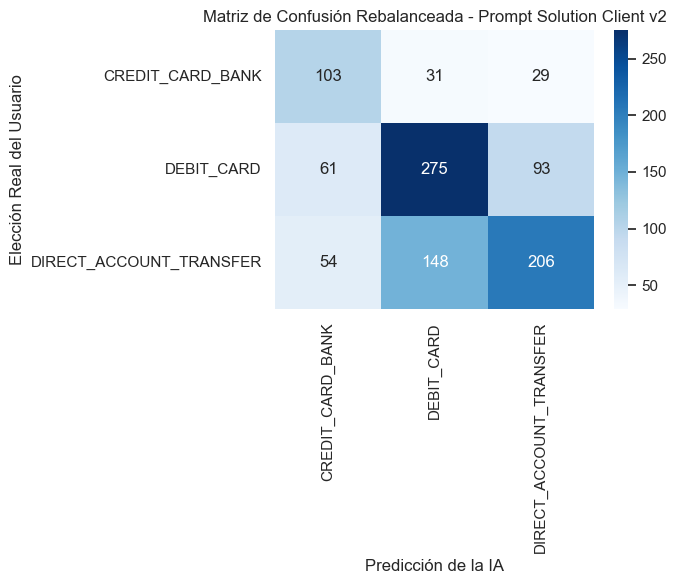

In [29]:
# FASE 5: EVALUACIÓN DEL MODELO Y MATRIZ DE CONFUSIÓN

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Inferencia sobre el set de prueba independiente (X_test)
y_pred_encoded = xgb_model.predict(X_test_processed)
y_pred_proba = xgb_model.predict_proba(X_test_processed)

# 2. Reporte de Clasificación y ROC-AUC Multi-Clase
print("--- REPORTE DE CLASIFICACIÓN BALANCEADO ---")
print(classification_report(y_test_encoded, y_pred_encoded, target_names=le.classes_))

auc_score = roc_auc_score(y_test_encoded, y_pred_proba, multi_class='ovr')
print(f"Área bajo la curva ROC (ROC-AUC Multi-Class): {auc_score:.4f}\n")

# 3. Gráfica de Matriz de Confusión
plt.figure(figsize=(7, 6))
cm = confusion_matrix(y_test_encoded, y_pred_encoded)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title('Matriz de Confusión Rebalanceada - Prompt Solution Client v2')
plt.xlabel('Predicción de la IA')
plt.ylabel('Elección Real del Usuario')
plt.tight_layout()
plt.show()

# FASE 5.1: Capa de Recomendación

In [30]:
# FASE 5.1: CAPA DE RECOMENDACIÓN (FUNCIÓN DE UTILIDAD / BUSINESS ENGINE)

def calcular_recomendacion_optima(row_data, modelo_pipeline, label_encoder):
    """
    Combina las probabilidades predictivas de XGBoost con el valor
    económico del incentivo ($COP) para emitir la recomendación final.
    """
    # 1. Inferencia del modelo (Propensión habitual del usuario)
    df_single = pd.DataFrame([row_data])
    probas = modelo_pipeline.predict_proba(df_single)[0]
    classes = label_encoder.classes_

    # 2. Extraer el valor del cashback en COP
    cashback_cop = row_data.get('incentive_value_cop', 0.0)

    # 3. Función de Utilidad: Elevar el score de Transferencia si el incentivo es atractivo
    scores = {}
    for cls, prob in zip(classes, probas):
        score = prob
        if cls == 'DIRECT_ACCOUNT_TRANSFER' and cashback_cop > 0:
            # Ponderador comercial: Aumenta la prioridad si el beneficio en $COP es real
            score += (cashback_cop / 100000.0)
        scores[cls] = score

    # Método recomendado que maximiza el valor para el usuario
    metodo_recomendado = max(scores, key=scores.get)

    return {
        'propensiones_ml': dict(zip(classes, [round(p, 2) for p in probas])),
        'cashback_cop': cashback_cop,
        'recomendacion_final': metodo_recomendado
    }

# Ejemplo de prueba en una transacción individual
ejemplo_tx = X_test.iloc[0].to_dict()
resultado = calcular_recomendacion_optima(ejemplo_tx, model_pipeline, le)

print("--- EJEMPLO DE LA ARQUITECTURA DE 2 CAPAS ---")
print("1. Probabilidades del Modelo (ML):", resultado['propensiones_ml'])
print("2. Valor del Incentivo ($COP):", f"${resultado['cashback_cop']:,.0f} COP")
print("3. Recomendación Final Sugerida en la App:", resultado['recomendacion_final'])

--- EJEMPLO DE LA ARQUITECTURA DE 2 CAPAS ---
1. Probabilidades del Modelo (ML): {'CREDIT_CARD_BANK': np.float32(0.01), 'DEBIT_CARD': np.float32(0.1), 'DIRECT_ACCOUNT_TRANSFER': np.float32(0.89)}
2. Valor del Incentivo ($COP): $17,000 COP
3. Recomendación Final Sugerida en la App: DIRECT_ACCOUNT_TRANSFER


## FASE 5.3: Demostración practica de función de utilidad

In [31]:
# FASE 5.3: EVALUACIÓN MASIVA DE LA CAPA DE RECOMENDACIÓN (N=1,000 TRANSACCIONES)

import pandas as pd
import numpy as np

# 1. Obtener probabilidades estimadas por XGBoost sobre todo el conjunto de prueba (X_test_processed)
probas_test = xgb_model.predict_proba(X_test_processed)
classes = le.classes_

w1, w2 = 0.50, 0.50  # Ponderación 50% Hábito ML / 50% Beneficio Comercial COP

masivo_resultados = []

for i in range(len(X_test)):
    row_data = X_test.iloc[i]
    p_est_vec = probas_test[i]

    cashback_cop = row_data.get('incentive_value_cop', 0.0)
    tx_amount = row_data['tx_amount']

    # Elección por Hábito (Capa 1 ML)
    pred_ml = classes[np.argmax(p_est_vec)]

    # Cálculo de la Función de Utilidad Comercial (Capa 2)
    utilidades = {}
    for idx, cls in enumerate(classes):
        p_est = p_est_vec[idx]
        ben_norm = (cashback_cop / 15000.0) if (cls == 'DIRECT_ACCOUNT_TRANSFER' and cashback_cop > 0) else 0.0
        u_score = (w1 * p_est) + (w2 * ben_norm)
        utilidades[cls] = u_score

    rec_final = max(utilidades, key=utilidades.get)

    hubo_sugerencia_activa = (pred_ml != rec_final)

    masivo_resultados.append({
        'tx_id': row_data.get('tx_id', f"TX-{i}"),
        'monto_cop': tx_amount,
        'incentivo_cop': cashback_cop,
        'prediccion_ml_habito': pred_ml,
        'recomendacion_utilidad': rec_final,
        'sugerencia_activa': hubo_sugerencia_activa
    })

df_masivo = pd.DataFrame(masivo_resultados)

# 2. Resumen Estadístico de Impacto Comercial
total_tx = len(df_masivo)
total_cambios = df_masivo['sugerencia_activa'].sum()
pct_cambios = (total_cambios / total_tx) * 100

print("="*85)
print(f"--- RESUMEN GLOBAL DE LA CAPA DE RECOMENDACIÓN (N={total_tx:,} TRANSACCIONES) ---")
print("="*85)
print(f" • Transacciones procesadas: {total_tx:,}")
print(f" • Coincidencia con el hábito habitual del cliente (Capa ML pura): {total_tx - total_cambios:,} ({(100 - pct_cambios):.1f}%)")
print(f" • Interrupciones comerciales para ahorro en $COP (Sugerencia activa): {total_cambios:,} ({pct_cambios:.1f}%)")
print("-" * 85)
print("\nMatriz de Transición (Predicción ML vs Recomendación Final):")
print(pd.crosstab(df_masivo['prediccion_ml_habito'], df_masivo['recomendacion_utilidad'], margins=True))

# Exportación directa de la tabla masiva evaluada en la Fase 5.4
df_masivo.to_excel("Validacion_Masiva_1000_Casos_Capa_Recomendacion.xlsx", index=False)

print("✅ Archivo 'Validacion_Masiva_1000_Casos_Capa_Recomendacion.xlsx' exportado para adjuntar a la tutora.")

--- RESUMEN GLOBAL DE LA CAPA DE RECOMENDACIÓN (N=1,000 TRANSACCIONES) ---
 • Transacciones procesadas: 1,000
 • Coincidencia con el hábito habitual del cliente (Capa ML pura): 897 (89.7%)
 • Interrupciones comerciales para ahorro en $COP (Sugerencia activa): 103 (10.3%)
-------------------------------------------------------------------------------------

Matriz de Transición (Predicción ML vs Recomendación Final):
recomendacion_utilidad   CREDIT_CARD_BANK  DEBIT_CARD  \
prediccion_ml_habito                                    
CREDIT_CARD_BANK                      170           0   
DEBIT_CARD                              0         399   
DIRECT_ACCOUNT_TRANSFER                 0           0   
All                                   170         399   

recomendacion_utilidad   DIRECT_ACCOUNT_TRANSFER   All  
prediccion_ml_habito                                    
CREDIT_CARD_BANK                              48   218  
DEBIT_CARD                                    55   454  
DIRECT_AC

## Fase 5.2: Evaluación de calibración de probabilidades

✅ Log Loss del Modelo: 0.8380

--- BRIER SCORE POR CLASE (Cercano a 0.0 indica alta calibración) ---
 - CREDIT_CARD_BANK: 0.1037
 - DEBIT_CARD: 0.2069
 - DIRECT_ACCOUNT_TRANSFER: 0.2042


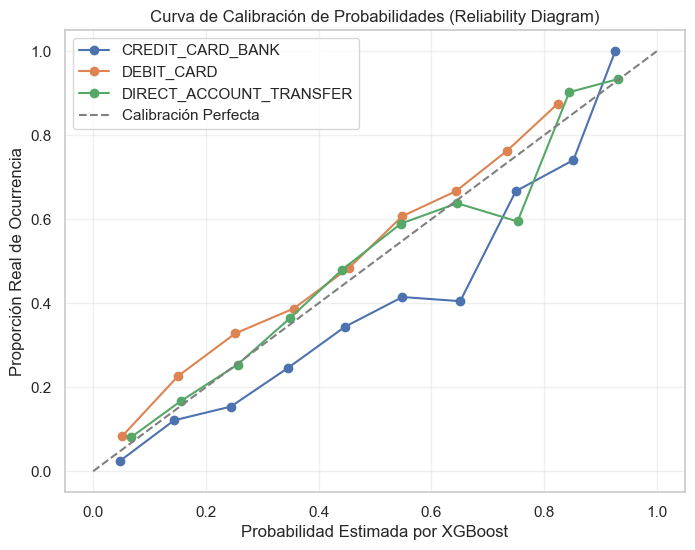

In [32]:
# FASE 5.2: EVALUACIÓN DE CALIBRACIÓN DE PROBABILIDADES (BRIER SCORE & LOG LOSS)

from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# 1. Log Loss Global
loss = log_loss(y_test_encoded, y_pred_proba)
print(f"✅ Log Loss del Modelo: {loss:.4f}")

# 2. Brier Score por Clase (One-vs-Rest)
print("\n--- BRIER SCORE POR CLASE (Cercano a 0.0 indica alta calibración) ---")
for idx, cls_name in enumerate(le.classes_):
    y_binary = (y_test_encoded == idx).astype(int)
    prob_cls = y_pred_proba[:, idx]
    b_score = brier_score_loss(y_binary, prob_cls)
    print(f" - {cls_name}: {b_score:.4f}")

# 3. Curva de Calibración (Reliability Diagram)
plt.figure(figsize=(8, 6))
for idx, cls_name in enumerate(le.classes_):
    y_binary = (y_test_encoded == idx).astype(int)
    prob_cls = y_pred_proba[:, idx]
    prob_true, prob_pred = calibration_curve(y_binary, prob_cls, n_bins=10)
    plt.plot(prob_pred, prob_true, marker='o', label=f'{cls_name}')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibración Perfecta')
plt.title('Curva de Calibración de Probabilidades (Reliability Diagram)')
plt.xlabel('Probabilidad Estimada por XGBoost')
plt.ylabel('Proporción Real de Ocurrencia')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Fase 6: Despliegue (Deployment / Exportación del Artefacto)

In [33]:
import joblib

# Exportar el pipeline completo y el codificador de etiquetas
joblib.dump(model_pipeline, 'model_payment_final.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("✅ Artefactos '.pkl' exportados.")

✅ Artefactos '.pkl' exportados.


## Fase de Probar Varios Modelos

In [34]:
# EVALUACIÓN Y COMPARATIVA MULTI-MODELO CONTRA BASELINE

import pandas as pd
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, brier_score_loss, f1_score, accuracy_score

# 1. Instanciar los 5 Modelos de Familias Distintas
models = {
    '1. Baseline (Dummy Stratified)': DummyClassifier(strategy='stratified', random_state=42),
    '2. Regresión Logística (Modelo Lineal)': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    '3. Random Forest (Bagging Ensemble)': RandomForestClassifier(n_estimators=150, max_depth=8, class_weight='balanced', random_state=42),
    '4. Red Neuronal MLP (Deep Learning)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

comparison_results = []

# 2. Bucle de Entrenamiento y Evaluación
for name, model in models.items():
    if 'XGBoost' in name:
        model.fit(X_train_resampled, y_train_resampled, sample_weight=sample_weights_train)
    elif 'Baseline' in name or 'MLP' in name:
        model.fit(X_train_resampled, y_train_resampled)
    else:
        model.fit(X_train_resampled, y_train_resampled)

    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)

    acc = accuracy_score(y_test_encoded, y_pred)
    f1_macro = f1_score(y_test_encoded, y_pred, average='macro')
    auc = roc_auc_score(y_test_encoded, y_proba, multi_class='ovr')

    # Brier Score promedio multi-clase
    brier_avg = np.mean([brier_score_loss((y_test_encoded == i).astype(int), y_proba[:, i]) for i in range(len(le.classes_))])

    comparison_results.append({
        'Algoritmo / Modelo': name,
        'Accuracy': round(acc, 4),
        'F1-Score Macro': round(f1_macro, 4),
        'ROC-AUC Multi-Class': round(auc, 4),
        'Brier Score Promedio': round(brier_avg, 4)
    })

# 3. Presentación de Resultados en Tabla
df_multi_model = pd.DataFrame(comparison_results)

print("="*95)
print("--- TABLA COMPARATIVA MULTI-MODELO ---")
print("="*95)
print(df_multi_model.to_string(index=False))

--- TABLA COMPARATIVA MULTI-MODELO ---
                    Algoritmo / Modelo  Accuracy  F1-Score Macro  ROC-AUC Multi-Class  Brier Score Promedio
        1. Baseline (Dummy Stratified)     0.335          0.3242               0.5038                0.4433
2. Regresión Logística (Modelo Lineal)     0.545          0.5433               0.7392                0.1858
   3. Random Forest (Bagging Ensemble)     0.558          0.5503               0.7448                0.1807
   4. Red Neuronal MLP (Deep Learning)     0.487          0.4787               0.6730                0.2808


c:\Users\juanp\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
